In [6]:
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp


def feature_diagnostics(df, name):
    return pd.DataFrame({
        "dataset": name,
        "feature": df.columns,
        "mean": df.mean().values,
        "std": df.std().values,
        "variance": df.var().values,
        "min": df.min().values,
        "q01": df.quantile(0.01).values,
        "q05": df.quantile(0.05).values,
        "q25": df.quantile(0.25).values,
        "median": df.quantile(0.50).values,
        "q75": df.quantile(0.75).values,
        "q95": df.quantile(0.95).values,
        "q99": df.quantile(0.99).values,
        "max": df.max().values,
        "missing_pct": df.isna().mean().values * 100,
        "unique_values": df.nunique(dropna=True).values,
    })

def range_tail_report(df_n, df_a):
    rows = []

    for f in df_n.columns:
        x_n = df_n[f].dropna()
        x_a = df_a[f].dropna()

        n_min = x_n.min()
        n_max = x_n.max()
        n_q01 = x_n.quantile(0.01)
        n_q05 = x_n.quantile(0.05)
        n_q95 = x_n.quantile(0.95)
        n_q99 = x_n.quantile(0.99)

        inside_minmax = (x_a >= n_min) & (x_a <= n_max)

        below_min = x_a < n_min
        above_max = x_a > n_max

        inside_5_95 = (x_a >= n_q05) & (x_a <= n_q95)
        below_q05 = x_a < n_q05
        above_q95 = x_a > n_q95

        inside_1_99 = (x_a >= n_q01) & (x_a <= n_q99)
        below_q01 = x_a < n_q01
        above_q99 = x_a > n_q99

        # "Inside range but in tails" means:
        # anomaly is still within normal min/max, but outside the normal 5%-95% central region.
        inside_range_but_tail_5_95 = inside_minmax & (~inside_5_95)

        rows.append({
            "feature": f,

            "normal_min": n_min,
            "normal_q01": n_q01,
            "normal_q05": n_q05,
            "normal_q95": n_q95,
            "normal_q99": n_q99,
            "normal_max": n_max,

            "anomaly_min": x_a.min(),
            "anomaly_max": x_a.max(),

            "anom_inside_normal_minmax_pct": inside_minmax.mean() * 100,
            "anom_below_normal_min_pct": below_min.mean() * 100,
            "anom_above_normal_max_pct": above_max.mean() * 100,

            "anom_inside_normal_5_95_pct": inside_5_95.mean() * 100,
            "anom_below_normal_q05_pct": below_q05.mean() * 100,
            "anom_above_normal_q95_pct": above_q95.mean() * 100,
            "anom_outside_normal_5_95_pct": (below_q05 | above_q95).mean() * 100,
            "anom_inside_range_but_tail_5_95_pct": inside_range_but_tail_5_95.mean() * 100,

            "anom_inside_normal_1_99_pct": inside_1_99.mean() * 100,
            "anom_outside_normal_1_99_pct": (below_q01 | above_q99).mean() * 100,
        })

    return pd.DataFrame(rows)

def ecdf(x):
    x = np.sort(x)
    y = np.arange(1, len(x) + 1) / len(x)
    return x, y


def plot_hist_and_ecdf(df_n, df_a, features, bins=100, chunk_size=5):
    # Loop through the features list in steps of `chunk_size`
    for i in range(0, len(features), chunk_size):
        chunk_features = features[i:i + chunk_size]
        n_features = len(chunk_features)

        # Create a new figure for this specific batch of features
        fig, axes = plt.subplots(
            n_features, 2,
            figsize=(14, 3 * n_features)
        )

        # Handle the edge case where the last chunk only has 1 feature left
        if n_features == 1:
            axes = np.array([axes])

        for row, feature in enumerate(chunk_features):
            x_n = df_n[feature].dropna().values
            x_a = df_a[feature].dropna().values

            # Shared bins
            combined = np.concatenate([x_n, x_a])
            bin_edges = np.histogram_bin_edges(combined, bins=bins)

            # Histogram
            ax = axes[row, 0]
            ax.hist(x_n, bins=bin_edges, density=True, alpha=0.5, label="normal")
            ax.hist(x_a, bins=bin_edges, density=True, alpha=0.5, label="slow/anomaly")
            ax.set_title(f"{feature} - histogram")
            ax.legend()

            # ECDF
            ax = axes[row, 1]
            xn_sorted, yn = ecdf(x_n)
            xa_sorted, ya = ecdf(x_a)

            ks_stat, p_value = ks_2samp(x_n, x_a)

            ax.plot(xn_sorted, yn, label="normal")
            ax.plot(xa_sorted, ya, label="slow/anomaly")
            ax.set_title(f"{feature} - ECDF | KS={ks_stat:.3f}")
            ax.set_ylabel("Cumulative probability")
            ax.legend()

        plt.tight_layout()
        plt.show()



    return ks_df

def get_ks_df(df_n, df_a, top_k = 10):
  ks_scores = []
  for col in df_n.columns:
      stat, p = ks_2samp(df_n[col].dropna(), df_a[col].dropna())
      ks_scores.append((col, stat, p))

  ks_df = pd.DataFrame(ks_scores, columns=["feature", "ks_stat", "p_value"])
  ks_df = ks_df.sort_values("ks_stat", ascending=False).head(top_k)

  return ks_df


def plot_most_separable_features(df_n, df_a, features):
    plot_hist_and_ecdf(df_n=df_n, df_a=df_a, features=features)

In [7]:
# ------------------------------------------------------------
# 1. Load data
# ------------------------------------------------------------

NORMAL_PATH = "data/KukaNormal.npy"
ANOMALY_PATH = "data/KukaSlow.npy"
COLUMNS_PATH = "data/KukaColumnNames.npy"


xn = np.load(NORMAL_PATH)
xa = np.load(ANOMALY_PATH)[:, : -1]
columns = np.load(COLUMNS_PATH)[:-1]


df_n = pd.DataFrame(xn, columns=columns)
df_a = pd.DataFrame(xa, columns=columns)

# **DATASET BASIC INFROMATIONS**

In [8]:
overview = pd.DataFrame({
    "dataset": ["normal", "slow/anomaly"],
    "rows": [df_n.shape[0], df_a.shape[0]],
    "features": [df_n.shape[1], df_a.shape[1]],
    "missing_values": [df_n.isna().sum().sum(), df_a.isna().sum().sum()],
    "inf_values": [np.isinf(df_n.values).sum(), np.isinf(df_a.values).sum()],
    "duplicate_rows": [df_n.duplicated().sum(), df_a.duplicated().sum()],
})

display(overview)

,dataset,rows,features,missing_values,inf_values,duplicate_rows
0,normal,233792,86,0,0,158
1,slow/anomaly,41538,86,0,0,16


In [9]:
# ------------------------------------------------------------
# 2. Basic feature diagnostics
# ------------------------------------------------------------

diag_n = feature_diagnostics(df_n, "normal")
diag_a = feature_diagnostics(df_a, "slow/anomaly")

# **ALMOST-CONSTANT FEATURES**

**Near-constant threshold:** `std < {LOW_VARIANCE_THRESHOLD}`

Una feature viene considerata quasi-constante quando la sua std è sotto una certa soglia. Queste sono quindi da considerare inutili per l'autoencoder, perchè non portano informazioni.

,feature,std,variance,min,max,unique_values,missing_pct,is_constant,is_near_constant
85,sensor_id7_temp,2.842177e-14,8.077970e-28,180.240000,180.240000,1,0.00%,False,True
74,sensor_id6_temp,2.842177e-14,8.077970e-28,180.240000,180.240000,1,0.00%,False,True
63,sensor_id5_temp,8.526531e-14,7.270173e-27,144.120000,144.120000,1,0.00%,False,True
30,sensor_id2_temp,8.526531e-14,7.270173e-27,144.120000,144.120000,1,0.00%,False,True
77,sensor_id7_AccZ,1.220245e-02,1.488997e-04,0.827148,1.143555,434,0.00%,False,False
76,sensor_id7_AccY,1.796907e-02,3.228876e-04,-0.224609,0.331543,543,0.00%,False,False
40,sensor_id3_q4,2.345308e-02,5.500470e-04,-0.081069,0.248984,228242,0.00%,False,False
6,machine_nameKuka Robot_power_factor,2.508125e-02,6.290689e-04,0.761271,0.924396,16419,0.00%,False,False
39,sensor_id3_q3,2.594895e-02,6.733480e-04,-0.115349,0.175234,228242,0.00%,False,False
3,machine_nameKuka Robot_frequency,3.204013e-02,1.026570e-03,49.902534,50.097847,5,0.00%,False,False


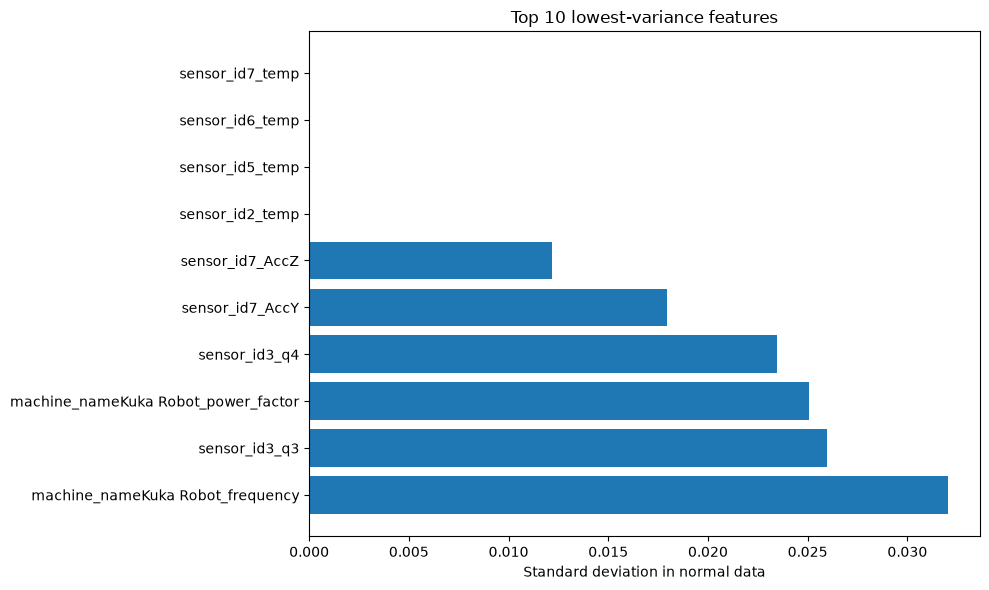

Constant features: 0
Near-constant features: 4


In [10]:
LOW_VARIANCE_THRESHOLD = 1e-8
TOP_K_LOW_VAR = 10

low_var_report_n = diag_n[[
    "feature", "std", "variance", "min", "max", "unique_values", "missing_pct"
]].copy()


low_var_report_n["is_constant"] = low_var_report_n["std"] == 0
low_var_report_n["is_near_constant"] = low_var_report_n["std"] < LOW_VARIANCE_THRESHOLD

low_var_report_n = low_var_report_n.sort_values("std", ascending=True)

display(
    low_var_report_n.head(TOP_K_LOW_VAR).style
    .background_gradient(subset=["std", "variance", "unique_values"], cmap="Blues")
    .format({
        "std": "{:.6e}",
        "variance": "{:.6e}",
        "min": "{:.6f}",
        "max": "{:.6f}",
        "missing_pct": "{:.2f}%",
    })
)

# Bar plot: lowest-variance features
plt.figure(figsize=(10, 6))
plot_df = low_var_report_n.head(TOP_K_LOW_VAR).iloc[::-1]
plt.barh(plot_df["feature"], plot_df["std"])
plt.xlabel("Standard deviation in normal data")
plt.title(f"Top {TOP_K_LOW_VAR} lowest-variance features")
plt.tight_layout()
plt.show()

constant_features = low_var_report_n.loc[low_var_report_n["is_constant"], "feature"].tolist()
near_constant_features = low_var_report_n.loc[low_var_report_n["is_near_constant"], "feature"].tolist()

print(f"Constant features: {len(constant_features)}")
print(f"Near-constant features: {len(near_constant_features)}")


,feature,std,variance,min,max,unique_values,missing_pct,is_constant,is_near_constant
30,sensor_id2_temp,9.140532e-11,8.354932e-21,144.120000,144.120000,1,0.00%,False,True
41,sensor_id3_temp,9.140532e-11,8.354932e-21,144.120000,144.120000,1,0.00%,False,True
63,sensor_id5_temp,9.140532e-11,8.354932e-21,144.120000,144.120000,1,0.00%,False,True
74,sensor_id6_temp,1.584814e-10,2.511634e-20,180.240000,180.240000,1,0.00%,False,True
85,sensor_id7_temp,1.584814e-10,2.511634e-20,180.240000,180.240000,1,0.00%,False,True
77,sensor_id7_AccZ,7.988283e-03,6.381267e-05,0.865234,1.206543,239,0.00%,False,False
76,sensor_id7_AccY,1.258236e-02,1.583158e-04,-0.169434,0.208496,328,0.00%,False,False
39,sensor_id3_q3,1.432303e-02,2.051493e-04,-0.047778,0.069972,40346,0.00%,False,False
71,sensor_id6_q2,2.357995e-02,5.560140e-04,-0.145241,0.073254,41400,0.00%,False,False
6,machine_nameKuka Robot_power_factor,2.488034e-02,6.190315e-04,0.757866,0.915870,3166,0.00%,False,False


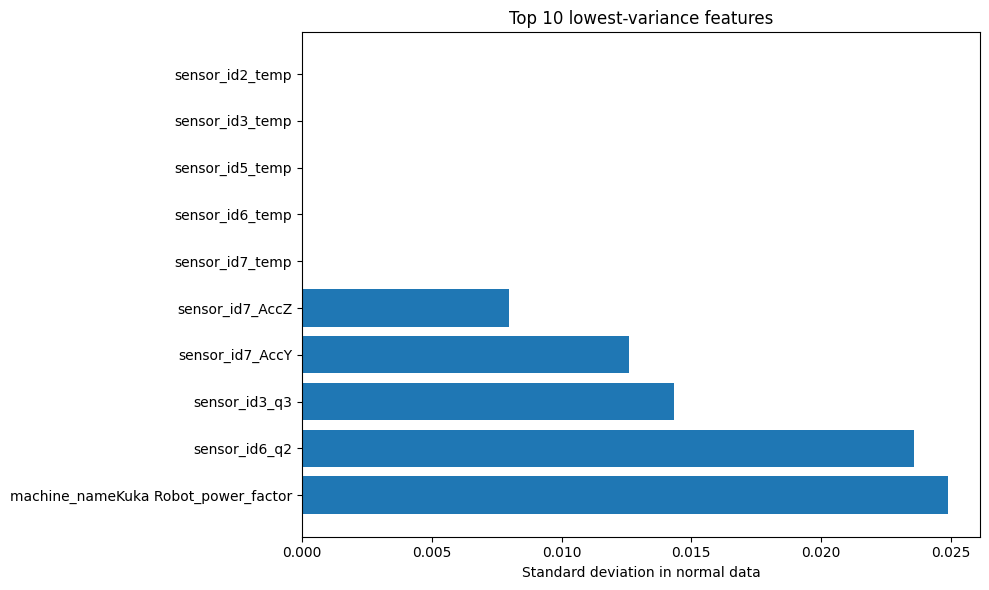

Constant features: 0
Near-constant features: 5


In [ ]:
low_var_report_a = diag_a[[
    "feature", "std", "variance", "min", "max", "unique_values", "missing_pct"
]].copy()


low_var_report_a["is_constant"] = low_var_report_a["std"] == 0
low_var_report_a["is_near_constant"] = low_var_report_a["std"] < LOW_VARIANCE_THRESHOLD

low_var_report_a = low_var_report_a.sort_values("std", ascending=True)

display(
    low_var_report_a.head(TOP_K_LOW_VAR).style
    .background_gradient(subset=["std", "variance", "unique_values"], cmap="Blues")
    .format({
        "std": "{:.6e}",
        "variance": "{:.6e}",
        "min": "{:.6f}",
        "max": "{:.6f}",
        "missing_pct": "{:.2f}%",
    })
)

# Bar plot: lowest-variance features
plt.figure(figsize=(10, 6))
plot_df = low_var_report_a.head(TOP_K_LOW_VAR).iloc[::-1]
plt.barh(plot_df["feature"], plot_df["std"])
plt.xlabel("Standard deviation in normal data")
plt.title(f"Top {TOP_K_LOW_VAR} lowest-variance features")
plt.tight_layout()
plt.show()

constant_features = low_var_report_a.loc[low_var_report_a["is_constant"], "feature"].tolist()
near_constant_features = low_var_report_a.loc[low_var_report_a["is_near_constant"], "feature"].tolist()

print(f"Constant features: {len(constant_features)}")
print(f"Near-constant features: {len(near_constant_features)}")

### **CONSIDERAZIONE SUI RISULTATI**

Dopo aver stampato la standard deviation di tutte le features e aver preso le 5 features con minore std, si può osservare che le seguenti features presentano un std bassissimo e quindi possono essere considerate pressocchè costanti:

- **SAMPLES NORMALI**

  | feature          | std          |
  |------------------|--------------|
  | sensor_id7_temp  | 1.502091e-10 |
  | sensor_id6_temp  | 1.502091e-10 |
  | sensor_id2_temp  | 3.284420e-10 |
  | sensor_id5_temp  | 3.284420e-10 |

- **SAMPLES ANOMALI**

  | feature          | std          |
  |------------------|--------------|
  | sensor_id2_temp  | 9.140532e-11 |
  | sensor_id3_temp  | 9.140532e-11 |
  | sensor_id5_temp  | 9.140532e-11 |
  | sensor_id6_temp  | 1.584814e-10 |
  | sensor_id7_temp  | 1.584814e-10 |

# **FEATURES RANGE ANALYSIS**

### Interpretazione

Per ogni feature:

* **`anom_inside_normal_minmax_pct`** indica con quale frequenza i valori lenti/anomali si trovano all'interno dell'intero intervallo min-max normale.
* **`anom_inside_normal_5_95_pct`** indica con quale frequenza i valori lenti/anomali si trovano all'interno della regione normale centrale.
* **`anom_outside_normal_5_95_pct`** indica con quale frequenza i valori lenti/anomali ricadono nelle code normali o oltre.
* **`anom_inside_range_but_tail_5_95_pct`** indica con quale frequenza i valori lenti/anomali rientrano ancora nell'intervallo min-max normale, ma si trovano esclusivamente nelle code normali.

Questo è utile perché un'anomalia può trovarsi all'interno dell'intervallo normale valido, ma comparire comunque in regioni a bassa densità.

In [11]:
# ------------------------------------------------------------
# 4. Range and tail report
# ------------------------------------------------------------

range_report = range_tail_report(df_n, df_a)

summary = pd.DataFrame({
    "metric": [
        "Average anomaly % inside normal min-max range",
        "Average anomaly % inside normal 5%-95% region",
        "Average anomaly % outside normal 5%-95% region",
        "Average anomaly % inside normal range but in 5%-95% tails",
        "Average anomaly % outside normal 1%-99% region",
    ],
    "value_pct": [
        range_report["anom_inside_normal_minmax_pct"].mean(),
        range_report["anom_inside_normal_5_95_pct"].mean(),
        range_report["anom_outside_normal_5_95_pct"].mean(),
        range_report["anom_inside_range_but_tail_5_95_pct"].mean(),
        range_report["anom_outside_normal_1_99_pct"].mean(),
    ]
})

print("Global summary across all features")
display(summary.style.format({"value_pct": "{:.2f}%"}))

Global summary across all features


,metric,value_pct
0,Average anomaly % inside normal min-max range,99.97%
1,Average anomaly % inside normal 5%-95% region,94.00%
2,Average anomaly % outside normal 5%-95% region,6.00%
3,Average anomaly % inside normal range but in 5%-95% tails,5.98%
4,Average anomaly % outside normal 1%-99% region,0.94%


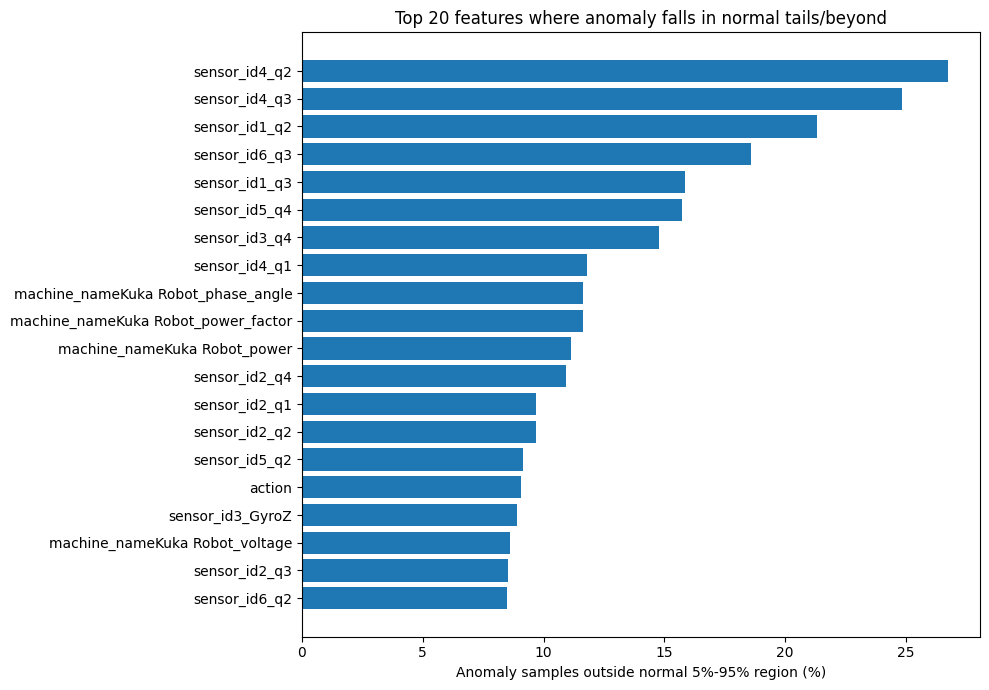

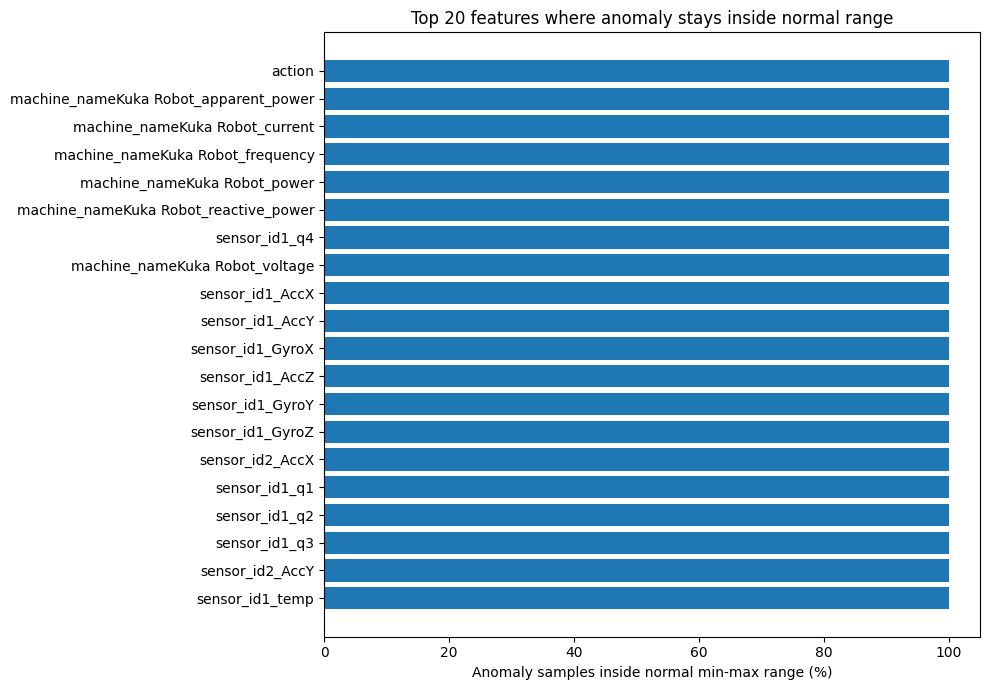

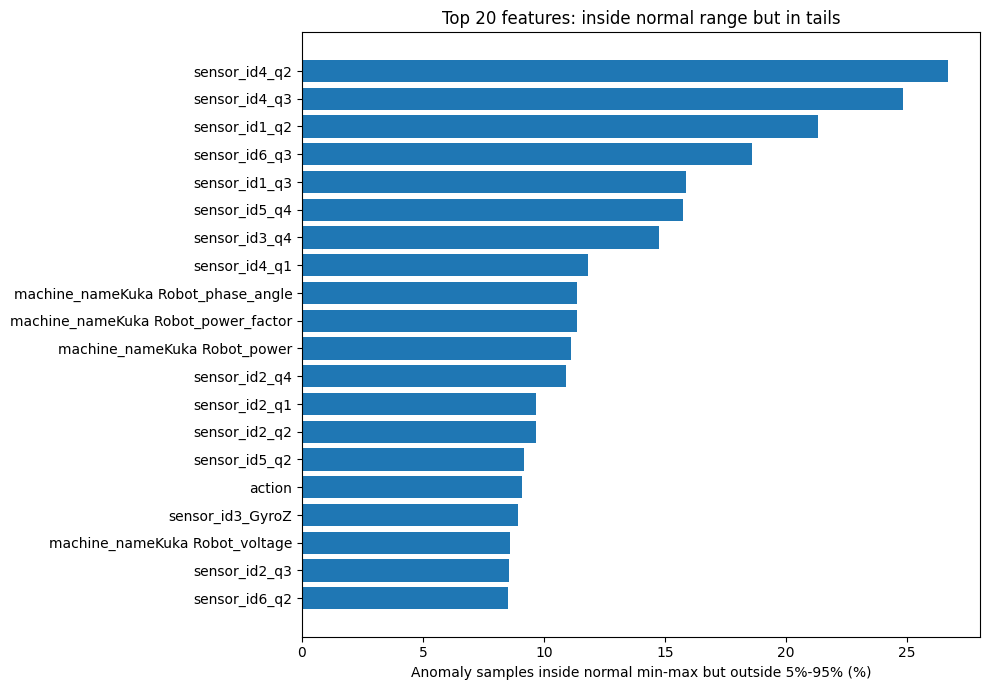

In [12]:
# ------------------------------------------------------------
# 5. Visualize range/tail behavior
# ------------------------------------------------------------

TOP_K = 20

# Top features where anomalies are most often outside the normal 5%-95% region
tail_top = range_report.sort_values(
    "anom_outside_normal_5_95_pct", ascending=False
).head(TOP_K)

plt.figure(figsize=(10, 7))
plt.barh(
    tail_top["feature"].iloc[::-1],
    tail_top["anom_outside_normal_5_95_pct"].iloc[::-1]
)
plt.xlabel("Anomaly samples outside normal 5%-95% region (%)")
plt.title(f"Top {TOP_K} features where anomaly falls in normal tails/beyond")
plt.tight_layout()
plt.show()


# Top features where anomalies are inside normal min-max range
inside_top = range_report.sort_values(
    "anom_inside_normal_minmax_pct", ascending=False
).head(TOP_K)

plt.figure(figsize=(10, 7))
plt.barh(
    inside_top["feature"].iloc[::-1],
    inside_top["anom_inside_normal_minmax_pct"].iloc[::-1]
)
plt.xlabel("Anomaly samples inside normal min-max range (%)")
plt.title(f"Top {TOP_K} features where anomaly stays inside normal range")
plt.tight_layout()
plt.show()


# Features where anomaly is inside range but concentrated in tails
inside_tail_top = range_report.sort_values(
    "anom_inside_range_but_tail_5_95_pct", ascending=False
).head(TOP_K)

plt.figure(figsize=(10, 7))
plt.barh(
    inside_tail_top["feature"].iloc[::-1],
    inside_tail_top["anom_inside_range_but_tail_5_95_pct"].iloc[::-1]
)
plt.xlabel("Anomaly samples inside normal min-max but outside 5%-95% (%)")
plt.title(f"Top {TOP_K} features: inside normal range but in tails")
plt.tight_layout()
plt.show()


### **CONSIDERAZIONI POST REPORT**

Dopo aver stampato il report delle feature con KS score maggiore si può osservare che i sample anomali,
per praticamente tutte e 10 le feature, ricadono all'interno del range `[min_normal, max_normal]` di valori che abbiamo per samples normali.

**Esempio:**

**FEATURE:** `sensor_id3_q1`

**PER SAMPLES NORMALI:**
- valore minimo = `-0.9999987292677391`
- valore massimo = `0.6122537990951888`

**PER SAMPLES ANOMALI:**
- valore minimo = `-0.9999863030997028`
- valore massimo = `-0.734394968606377`

Come si può vedere, il range assunto per samples anomali ricade all'interno del range per samples normali, perciò non è facile comprendere esclusivamente l'anomalia dal valore, ma probabilmente bisognerà guardare qualcosa legato a **FREQUENZA, TIMING, FASE (CICLICITÀ)**.

# **TAIL RESIDENCE**

Osserviamo quanto i dati rimangono all'esterno del range 5%-95%. Questo è utile perchè in un comportamento sano, la misurazione può assumere valori agli estremi (es. la coppia del motore schizza al 97° percentile) ma questo succede per breve tempo e poi torna nel range normale. In caso di malfunzionamenti, alcuni valori potrebbero schizzare ad uno dei due estremi, per rimanerci un tempo prolungato. 

Oppure dall'altro punto di vista, potrebbe succedere che il robot debba mantenere un determinato valore per un tempo x, e in caso di anomalia questo valore venga mantenuto per meno tempo del necessario.

In [11]:
def run_lengths(mask):
    """
    mask: boolean array
    returns lengths of consecutive True runs
    """
    mask = np.asarray(mask).astype(bool)

    if len(mask) == 0:
        return np.array([])

    padded = np.concatenate([[False], mask, [False]])
    changes = np.diff(padded.astype(int))

    starts = np.where(changes == 1)[0]
    ends = np.where(changes == -1)[0]

    return ends - starts


def tail_residence_report(df_n, df_a, q_low=0.05, q_high=0.95):
    rows = []

    for f in df_n.columns:
        x_n = df_n[f].dropna()
        x_a = df_a[f].dropna()

        low_thr = x_n.quantile(q_low)
        high_thr = x_n.quantile(q_high)

        n_tail = (df_n[f] < low_thr) | (df_n[f] > high_thr)
        a_tail = (df_a[f] < low_thr) | (df_a[f] > high_thr)

        n_runs = run_lengths(n_tail.values)
        a_runs = run_lengths(a_tail.values)

        rows.append({
            "feature": f,
            "normal_tail_pct": n_tail.mean() * 100,
            "anomaly_tail_pct": a_tail.mean() * 100,

            "normal_max_tail_run": n_runs.max() if len(n_runs) else 0,
            "anomaly_max_tail_run": a_runs.max() if len(a_runs) else 0,

            "normal_mean_tail_run": n_runs.mean() if len(n_runs) else 0,
            "anomaly_mean_tail_run": a_runs.mean() if len(a_runs) else 0,

            "tail_pct_ratio_anom_vs_normal": (
                a_tail.mean() / n_tail.mean() if n_tail.mean() > 0 else np.nan
            ),

            "max_run_ratio_anom_vs_normal": (
                (a_runs.max() / n_runs.max())
                if len(n_runs) and n_runs.max() > 0 and len(a_runs)
                else np.nan
            ),
        })

    return pd.DataFrame(rows).sort_values(
        ["max_run_ratio_anom_vs_normal", "tail_pct_ratio_anom_vs_normal"],
        ascending=False
    )


tail_report = tail_residence_report(df_n, df_a)

display(
    tail_report.head(30).style
    .background_gradient(
        subset=[
            "anomaly_tail_pct",
            "anomaly_max_tail_run",
            "tail_pct_ratio_anom_vs_normal",
            "max_run_ratio_anom_vs_normal",
        ],
        cmap="Oranges"
    )
    .format({
        "normal_tail_pct": "{:.2f}%",
        "anomaly_tail_pct": "{:.2f}%",
        "normal_mean_tail_run": "{:.2f}",
        "anomaly_mean_tail_run": "{:.2f}",
        "tail_pct_ratio_anom_vs_normal": "{:.2f}",
        "max_run_ratio_anom_vs_normal": "{:.2f}",
    })
)

,feature,normal_tail_pct,anomaly_tail_pct,normal_max_tail_run,anomaly_max_tail_run,normal_mean_tail_run,anomaly_mean_tail_run,tail_pct_ratio_anom_vs_normal,max_run_ratio_anom_vs_normal
29,sensor_id2_q4,10.00%,10.94%,57,97,40.24,49.93,1.09,1.70
49,sensor_id4_q2,10.00%,26.73%,91,137,26.57,53.38,2.67,1.51
40,sensor_id3_q4,10.00%,14.78%,52,71,7.65,10.83,1.48,1.37
32,sensor_id3_AccY,10.00%,5.45%,8,10,1.47,1.37,0.55,1.25
27,sensor_id2_q2,10.00%,9.69%,65,81,20.24,26.31,0.97,1.25
67,sensor_id6_GyroX,9.91%,4.69%,5,6,2.62,2.58,0.47,1.20
21,sensor_id2_AccY,9.97%,4.43%,5,6,1.65,1.66,0.44,1.20
24,sensor_id2_GyroY,9.99%,2.23%,10,11,3.47,2.94,0.22,1.10
22,sensor_id2_AccZ,9.25%,7.44%,12,13,1.98,2.12,0.80,1.08
44,sensor_id4_AccZ,9.36%,7.17%,12,13,1.95,2.20,0.77,1.08


### **CONSIDERAZIONI**

Per definizione matematica, se prendiamo un set di dati e ne calcoli questi percentili, il 10% esatto dei campioni si troverà sempre in quelle code (5% sotto, 5% sopra). In questo caso, molte features presentano una permanenza nelle code differente da 10% (permanenza maggiore o minore) quindi questo ci suggerisce una possibile problematica.

es: guardando il dato `[normal-anomaly]_max_tail_run` (che misura la striscia di campioni consecutivi, più lunga, le cui misurazioni ricadono nelle code) per la feature `sensor_id4_q2` si può vedere come la striscia più lunga nel caso anomalo sia 137 (+46 rispetto al caso normale) e quindi ci fa vedere una maggiore permanenza nella coda.

# **Kolmogorov-Smirnov ANALYSIS**

Lo **score KS (Kolmogorov-Smirnov)** è una statistica che misura quanto due distribuzioni di probabilità differiscono tra loro.

**Come funziona**

1. Prende le funzioni di distribuzione cumulata (CDF) di due campioni (o di un campione confrontato con una distribuzione teorica).
2. Calcola la **distanza massima verticale** tra le due curve CDF, punto per punto.
3. Quel valore massimo è lo score KS: un numero tra 0 e 1.
   - **KS vicino a 0** → le due distribuzioni sono molto simili.
   - **KS vicino a 1** → le due distribuzioni sono molto diverse.

**A cosa serve, in pratica**:
- **Feature selection / classificazione binaria**: nel machine learning, il KS può misurare quanto bene una feature separa due classi (es. distribuzione dei valori per la classe positiva vs negativa) — più alto è il KS, più la feature è discriminante.

- **Confronto tra due campioni**: verificare se provengono dalla stessa distribuzione (es. dati di training vs dati di produzione, per rilevare *data drift*).


In [13]:
ks_df = get_ks_df(df_n, df_a)
features = ks_df["feature"].tolist()

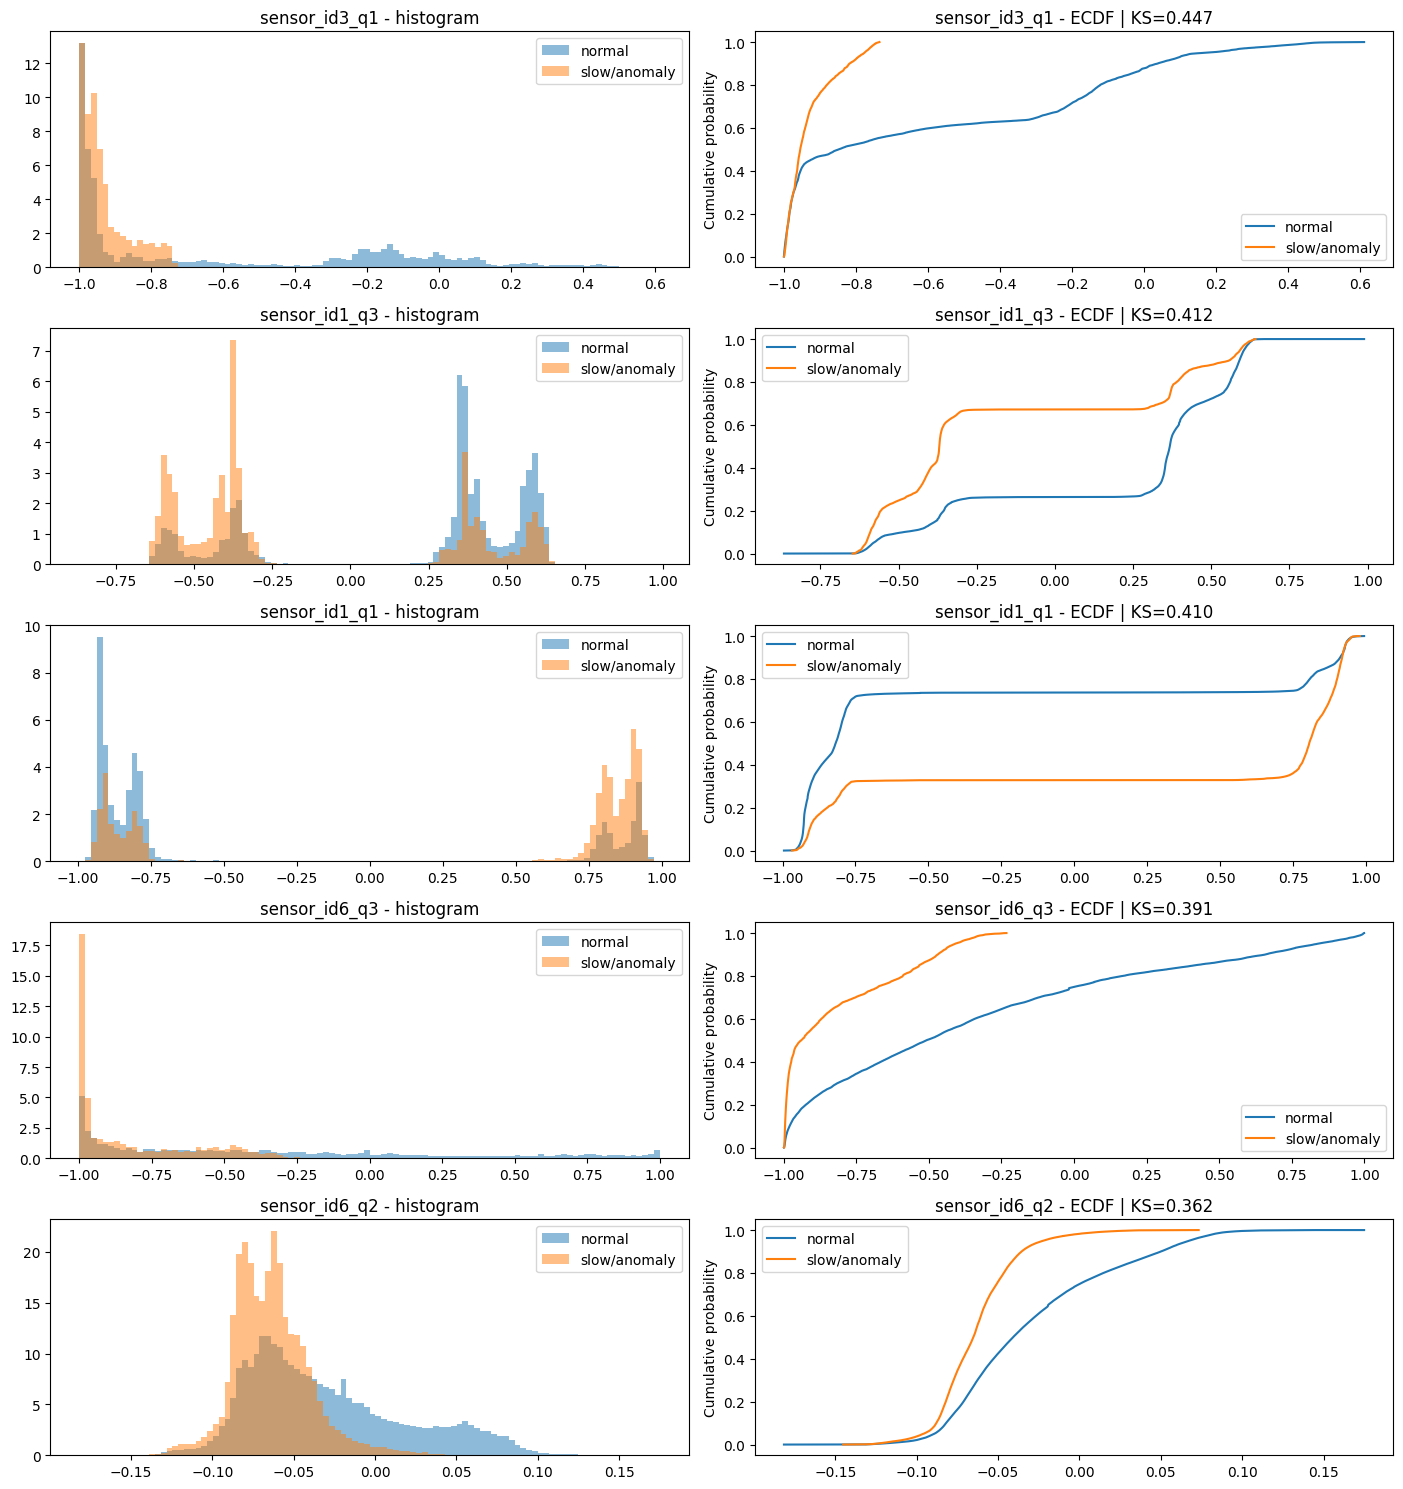

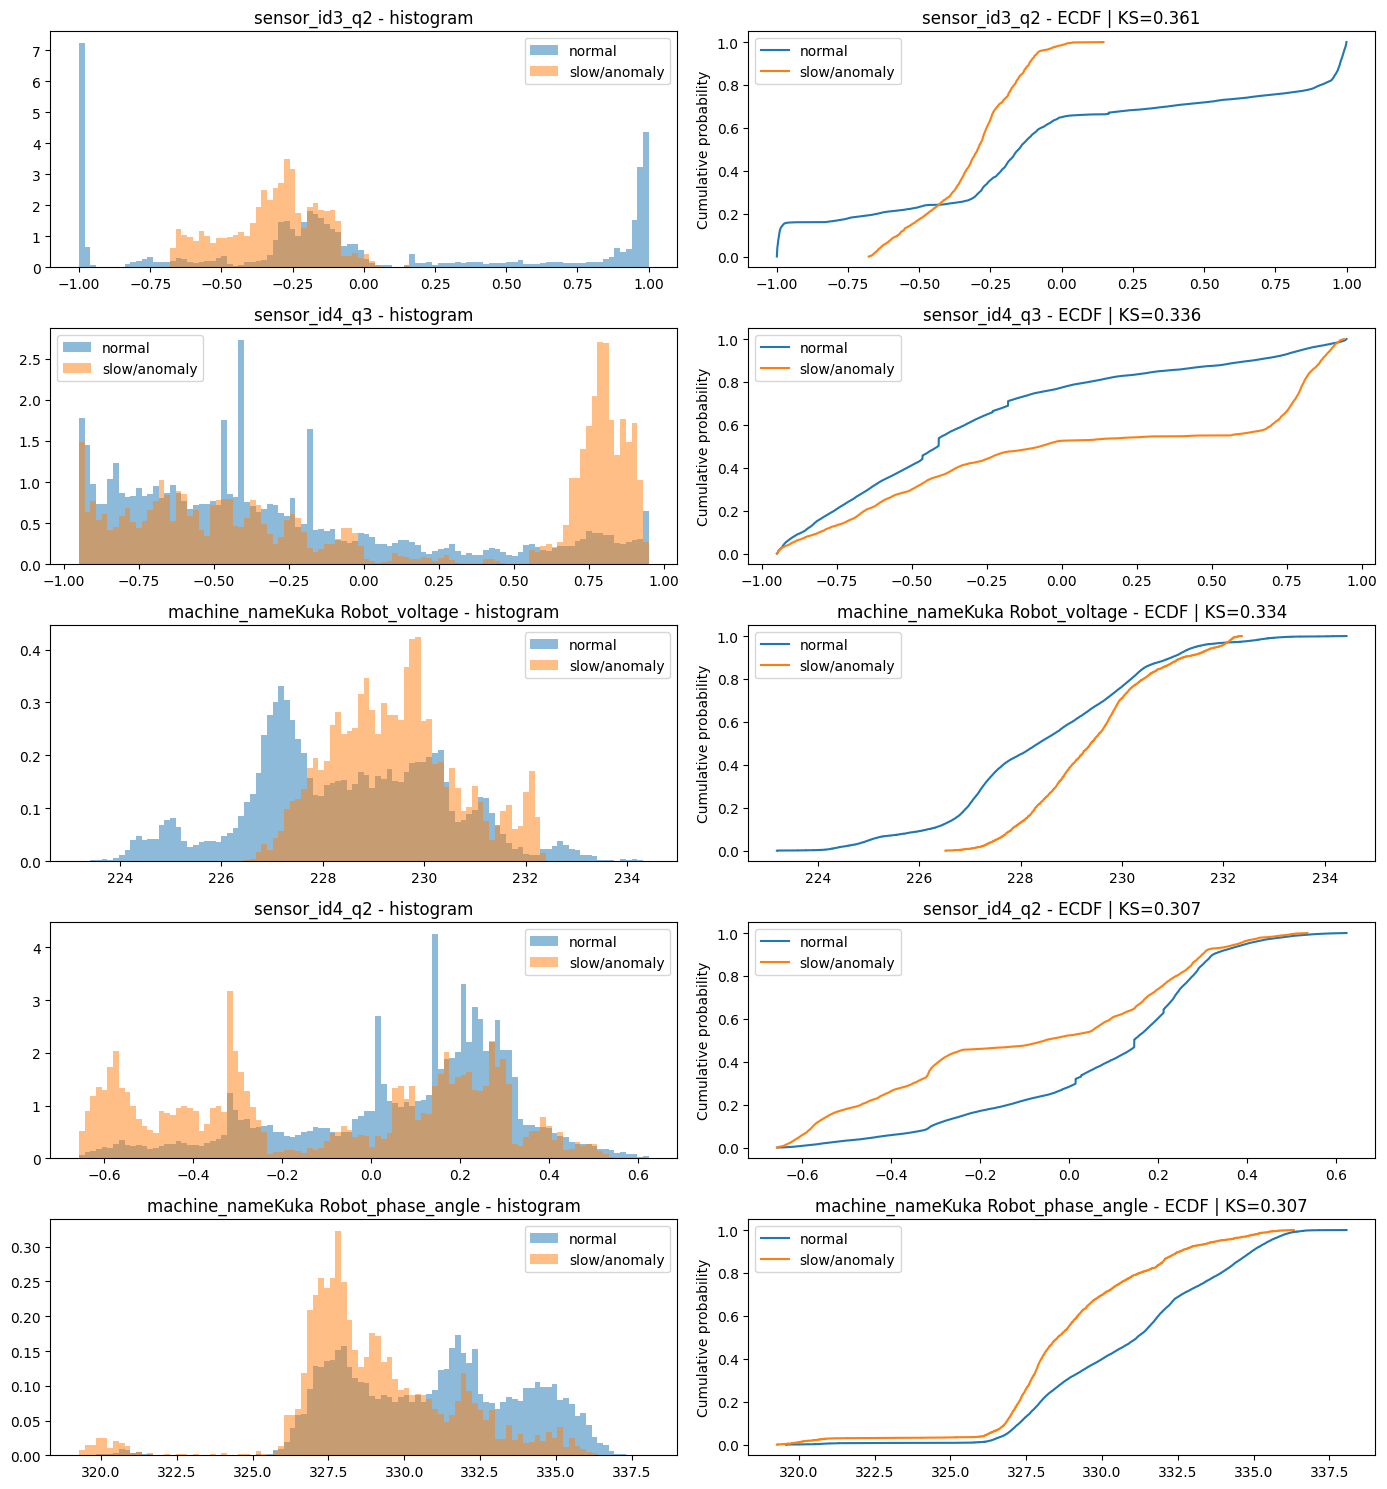

In [14]:
plot_most_separable_features(df_n, df_a, features)

# **TEMPORAL ANALYSIS**

Con una line plot, possiamo effettivamente andare a vedere il comportamento fisico.

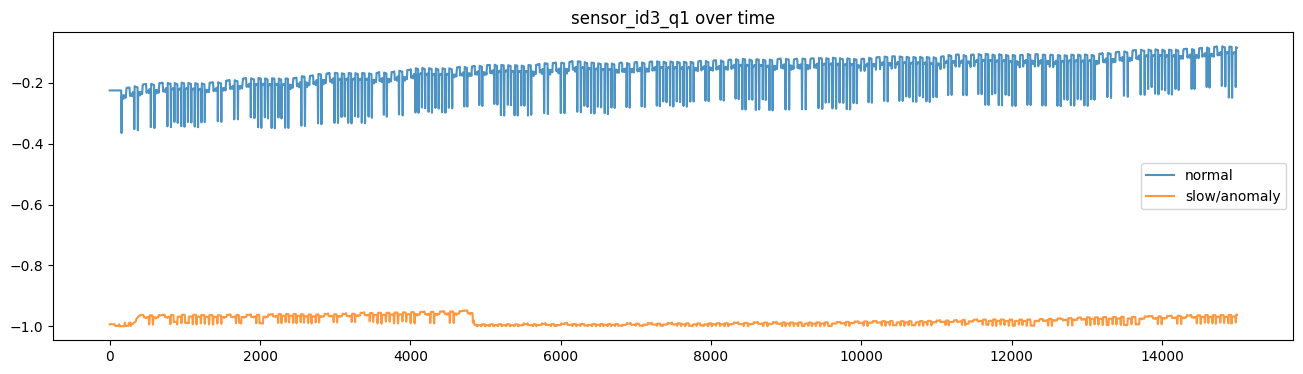

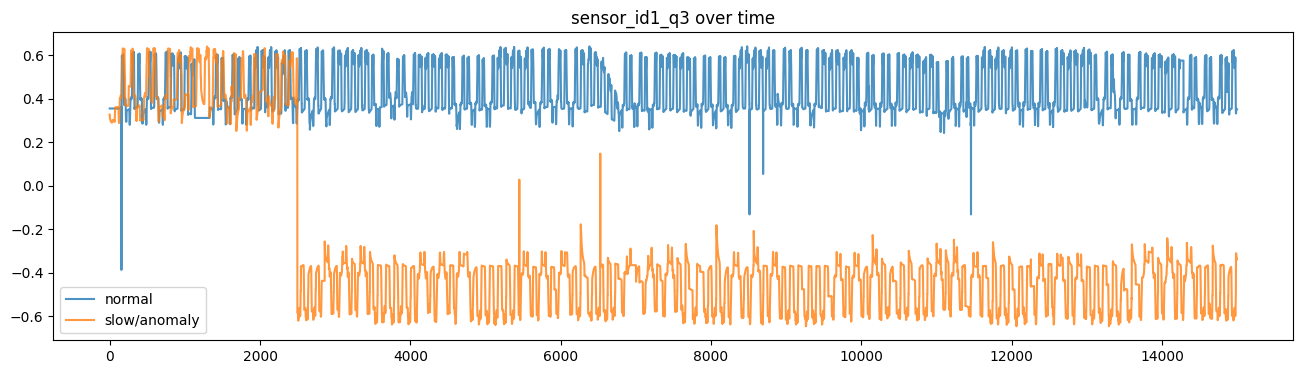

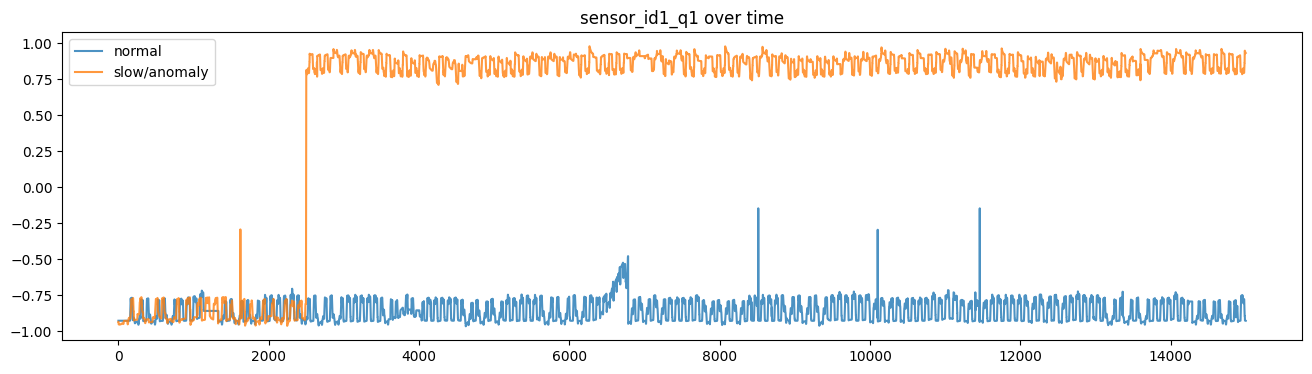

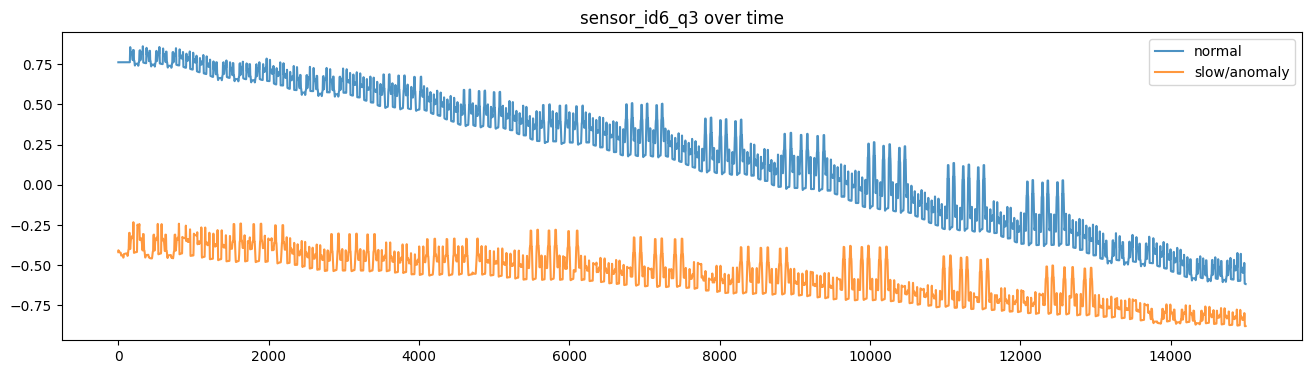

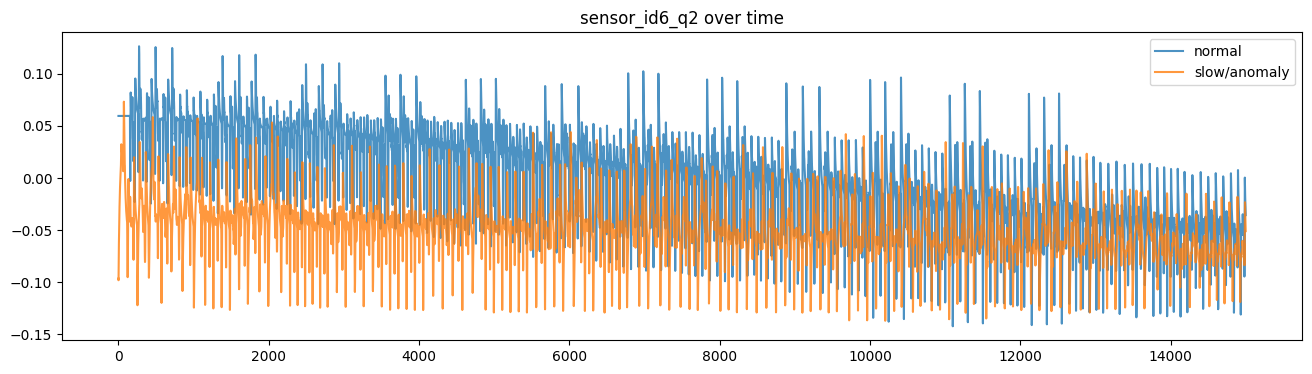

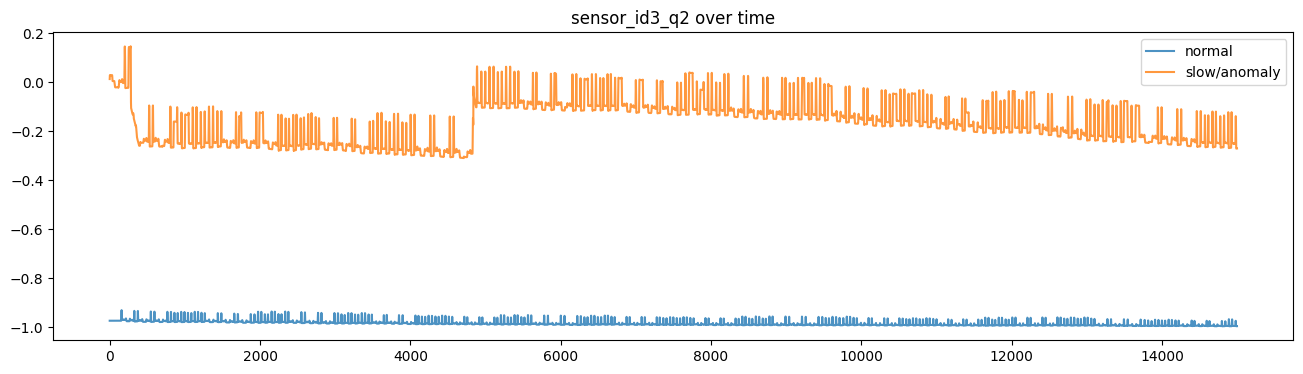

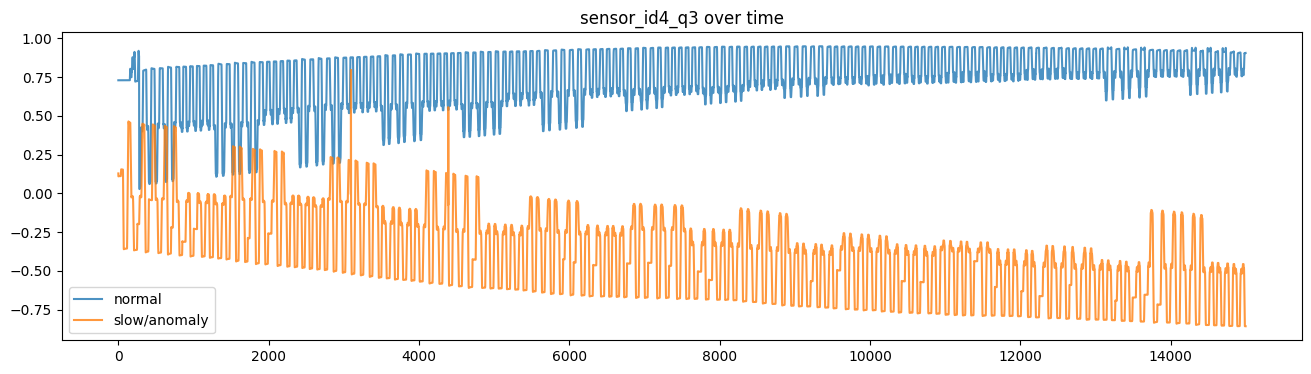

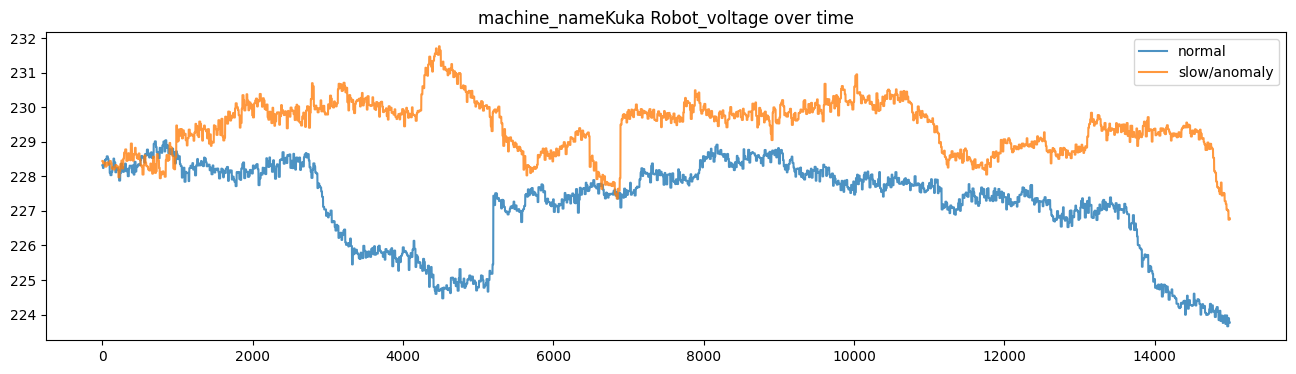

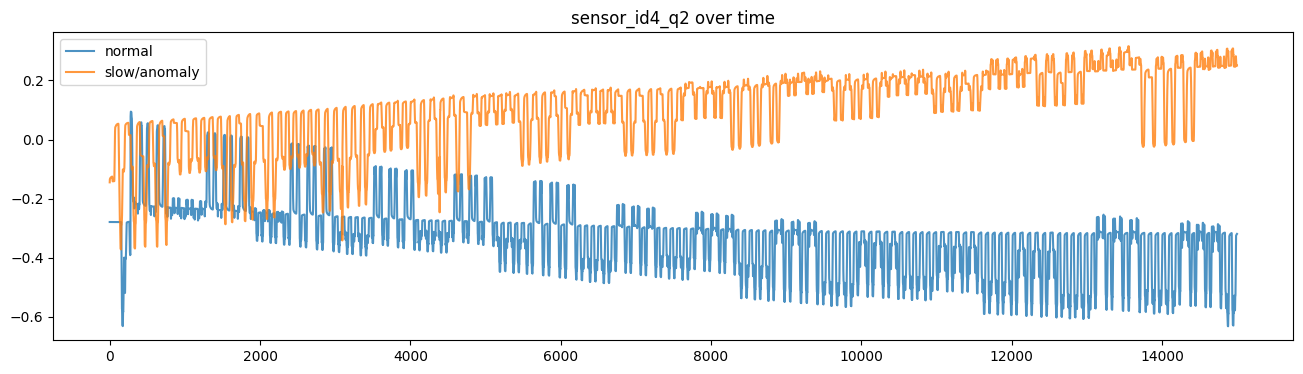

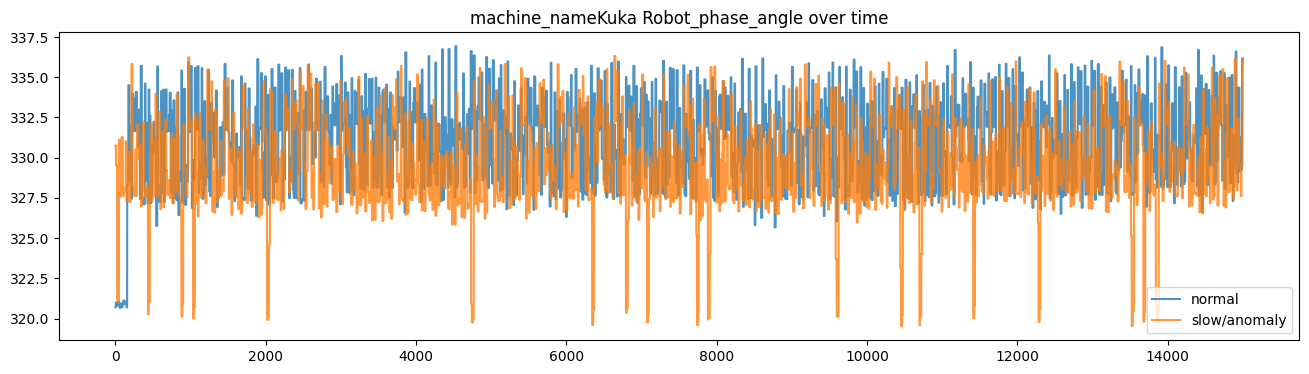

In [15]:
for f in features:
    plt.figure(figsize=(16, 4))
    plt.plot(df_n[f].values[:15000], label="normal", alpha=0.8)
    plt.plot(df_a[f].values[:15000], label="slow/anomaly", alpha=0.8)
    plt.title(f"{f} over time")
    plt.legend()
    plt.show()

### **ANALISI PLOT**
Le situazioni che si sono presentate sono:
- **shift posizionale**: i valori anomali sono spesso traslati rispetto alla versione normale, che, nel caso delle misurazioni di sensori posizionati nei joint q (q1, q2...), significa che il braccio è posizionato male, spostato rispetto alla posizione normale.
- **assenza di movimento**: in alcun casi la misurazione nel tempo diventa una linea retta, il che, nel caso dei joint, singifica che non c'è alcun movimento
- **inversione dei picchi**: per alcune feature nel passaggio da anomalia a misurazione normale, il braccio robotico presenta dei picchi rivolti in direzione opposta

    (es: guardare grafico `sensors_id6_q2`, per sample normali, i picchi blu sono rivolti verso l'alto, cioè che i giunto subisce delle accelerazioni/spostamenti improvvisi in direzione positiva. Per i sample anomali, invece, i picchi sono rivolti verso il basso[-0.10/-0.15], cioè le variazioni di posizione avvengono in direzione opposta )
   
   Questo potrebbe succedere quando il braccio deve bilanciare uno sbilanciamento

# **FIRST-DIFFERENCE ANALYSIS**
`.diff()` calcola la differenza tra il valore assunto da una feature al tempo t e il suo valore al tempo t-1. Questo è equivalente a calcolare la derviata discreta, quindi il significato del risultato cambia a seconda del significato della feature:
- se la feature era **posizionale** (es. l'angolo di un giunto), il $\Delta$ rappresenta la *velocità*
- se la feature è la **velocità**, il $\Delta$ rappresenta l'*accelerazione*.
- se la feature è la **coppia** (torque) o la **corrente**, il $\Delta$ rappresenta la variazione istantanea di sforzo (utile per identificare strappi o picchi di assorbimento).

Inoltre è stato impostato `density=True` quindi stiamo confrontando le funzioni di densità di probabilità delle due condizioni (normale vs slow).

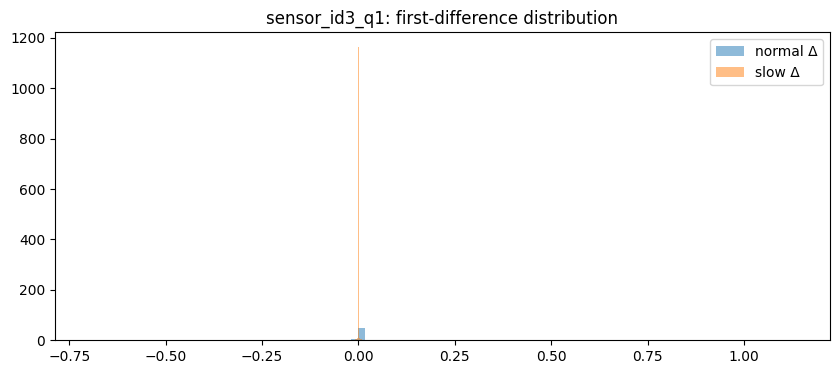

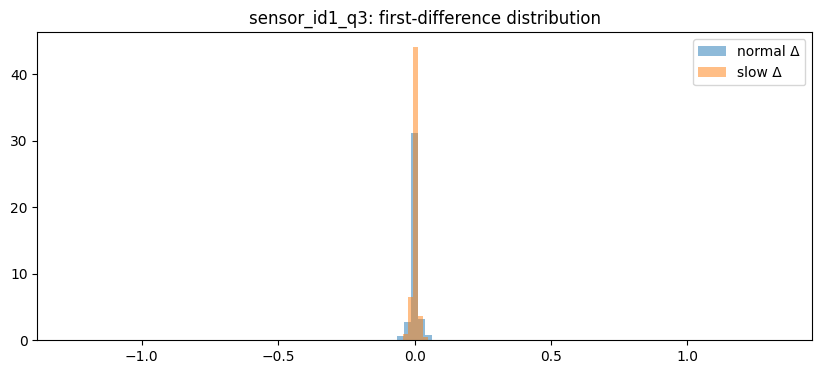

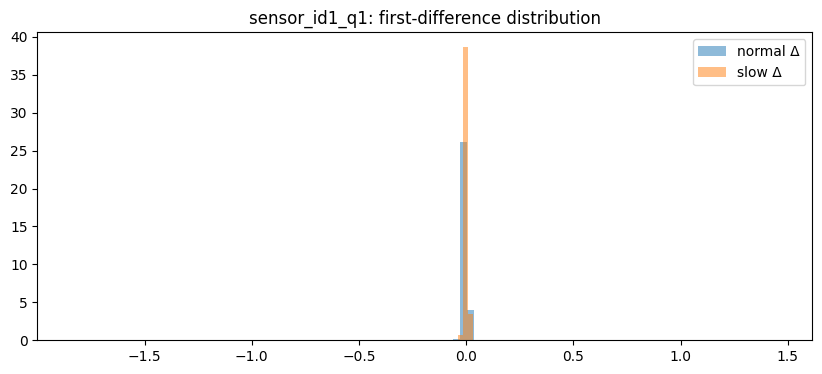

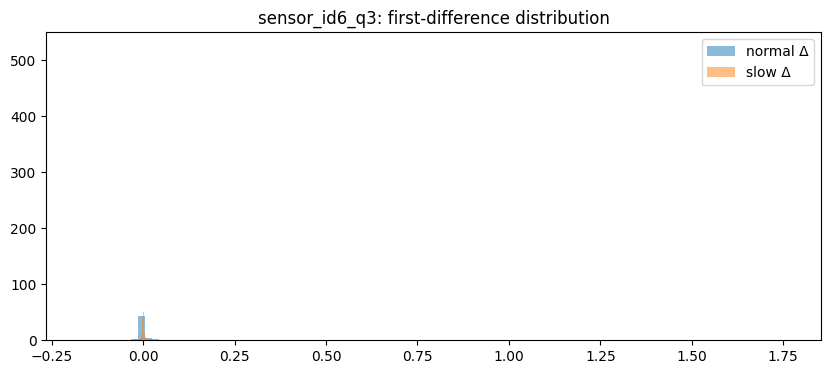

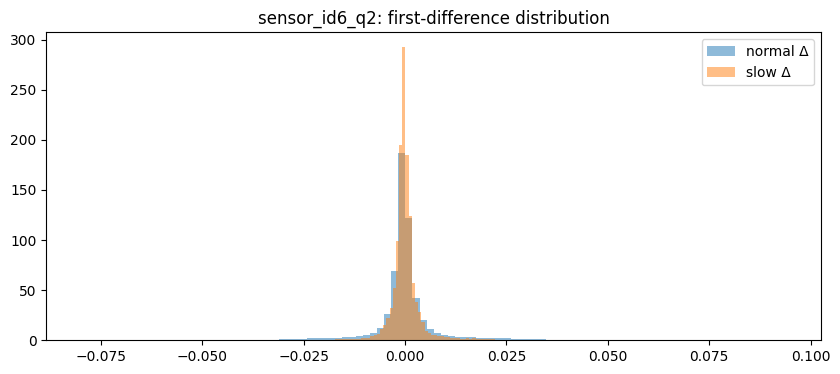

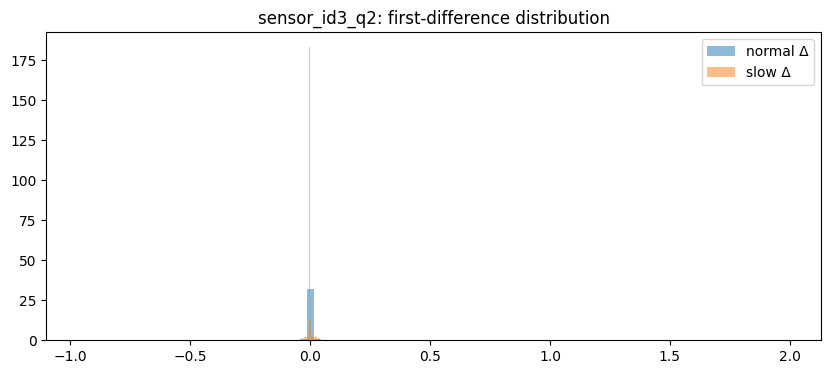

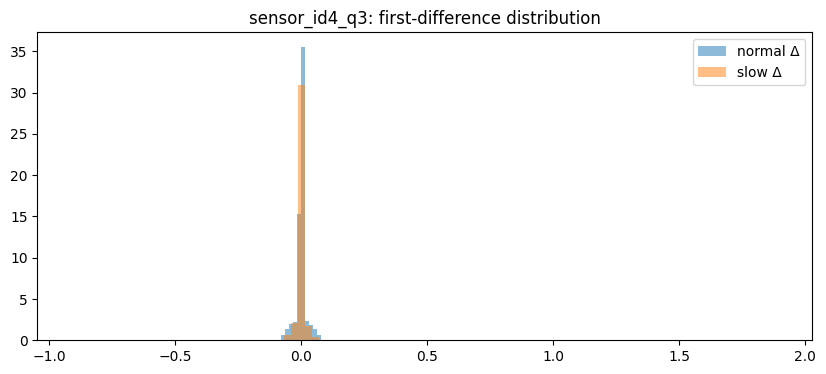

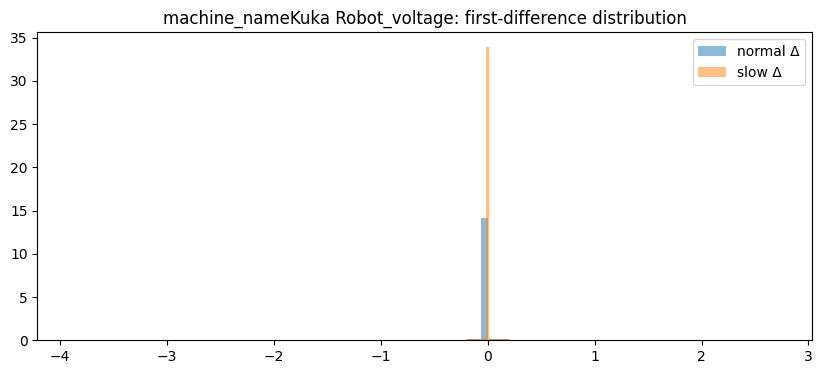

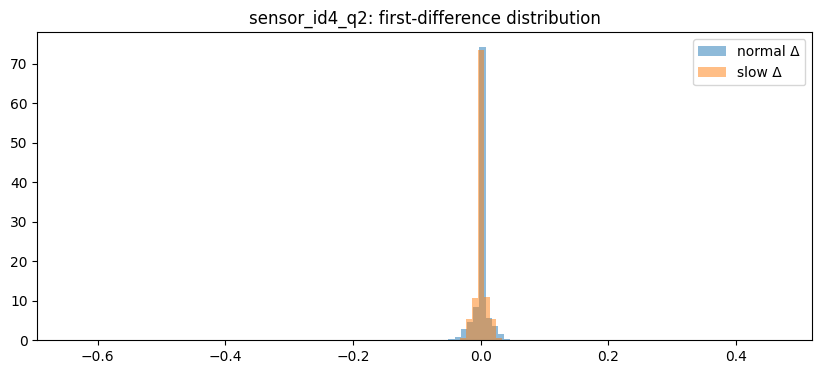

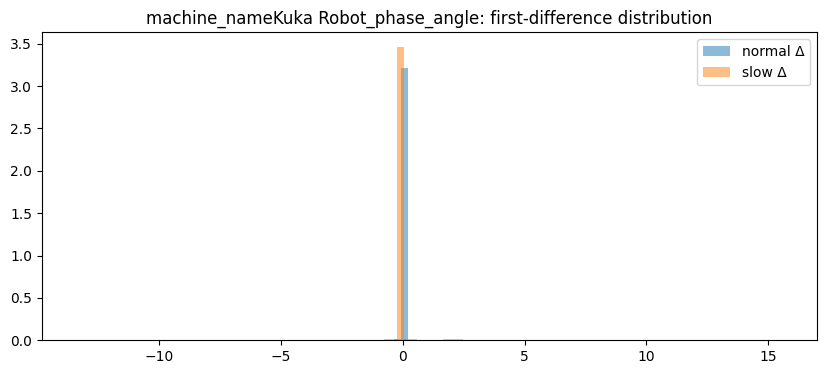

In [16]:
for f in features:
    dn = df_n[f].diff().dropna()
    da = df_a[f].diff().dropna()

    plt.figure(figsize=(10, 4))
    plt.hist(dn, bins=100, alpha=0.5, density=True, label="normal Δ")
    plt.hist(da, bins=100, alpha=0.5, density=True, label="slow Δ")
    plt.title(f"{f}: first-difference distribution")
    plt.legend()
    plt.show()

### **ANALISI DEI PLOT**

Ecco i tre pattern che abbiamo incontrato e i loro significati

- **La distribuzione "slow" è più stretta e alta (concentrata sullo zero)**:

  - *Cosa significa*: I valori cambiano molto meno tra un campionamento e l'altro.

  - *Interpretazione*: Questo è il comportamento atteso da un'anomalia puramente "slow". Se il robot viaggia a velocità ridotta (es. a causa di un safety override o un rallentamento imposto dal PLC), la variazione di posizione o velocità per ogni tick temporale sarà molto più piccola.

- **La distribuzione "slow" ha le "code" più grosse (Fatter tails)**:

   - *Cosa significa*: Ci sono più valori estremi (positivi e negativi) nel tasso di variazione.

   - *Interpretazione*: Questo indica un movimento a scatti o vibrante. Se l'anomalia è causata da usura meccanica, attrito, o un giunto danneggiato, il robot farà fatica a mantenere un moto fluido. Anche se il movimento globale è "lento", micro-istante per micro-istante il sistema subisce brusche frenate e accelerazioni, allargando l'istogramma.

- **Le distribuzioni sono "disassate" (Shift della media)**:

  - *Cosa significa*: I picchi centrali dei due istogrammi non sono allineati.

  - *Interpretazione*: C'è un drift o una tendenza direzionale anomala. Nel caso di posizioni, significa che il robot sta deviando; nel caso di correnti, significa che il motore sta costantemente aumentando o diminuendo lo sforzo in una direzione specifica rispetto alla baseline.